# Module 09, Part 5: From reinforcement learning to alignment, RLHF and DPO

This notebook is the runnable companion to Part 5 of the Module 09 learning content. It checks, with code, the ideas behind training a language model from human preferences, in a setting small enough to solve exactly:

1. That a reward model can be learned from pairwise comparisons alone, and how many comparisons it takes.
2. That the policy which maximizes reward minus a KL penalty towards a reference policy has a closed form, and that it trades reward for distance from the reference.
3. That optimizing a *learned* reward too hard makes the true reward fall: reward hacking.
4. That Direct Preference Optimization reaches the same policy as "learn a reward model, then optimize against it" without ever fitting a reward model.

**Setting.** Six prompts, and for each prompt a menu of eight candidate responses. The true quality of a response is a number drawn from a standard normal, which a labeller can see but we cannot. A labeller prefers response $i$ to response $j$ with probability $\sigma(r_i - r_j)$, the Bradley-Terry model, so labels are noisy. A *policy* is a table of probabilities over the eight responses for each prompt, defined by logits. The reference policy is uniform, which stands in for the pretrained model.

In [1]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
torch.set_num_threads(1)
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import numpy as np
import torch
import torch.nn.functional as F


class PreferenceWorld:
    """n_prompts prompts, n_resp responses each. The true reward of a response is drawn from a standard normal.
    A labeller prefers response i over j with probability sigmoid(r_i - r_j) (the Bradley-Terry model)."""
    def __init__(self, n_prompts=6, n_resp=8, seed=0):
        rng = np.random.default_rng(seed)
        self.n_prompts, self.n_resp = n_prompts, n_resp
        self.true_r = torch.as_tensor(rng.normal(0, 1, (n_prompts, n_resp)), dtype=torch.float32)
        self.rng = rng

    def sample_pairs(self, n):
        """Return prompt, winner and loser indices for n labelled comparisons."""
        p = self.rng.integers(0, self.n_prompts, n)
        i = self.rng.integers(0, self.n_resp, n)
        j = (i + self.rng.integers(1, self.n_resp, n)) % self.n_resp
        pi = torch.sigmoid(self.true_r[p, i] - self.true_r[p, j]).numpy()
        i_wins = self.rng.random(n) < pi
        w = np.where(i_wins, i, j); l = np.where(i_wins, j, i)
        return torch.as_tensor(p), torch.as_tensor(w), torch.as_tensor(l)


def fit_reward_model(world, p, w, l, steps=400, lr=0.1, l2=0.0):
    """Fit a reward table by maximizing the Bradley-Terry likelihood of the labelled preferences."""
    r = torch.zeros(world.n_prompts, world.n_resp, requires_grad=True)
    opt = torch.optim.Adam([r], lr=lr)
    for _ in range(steps):
        loss = -F.logsigmoid(r[p, w] - r[p, l]).mean() + l2 * (r ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return r.detach()


def kl_regularized_optimum(ref_logits, reward, beta):
    """The policy that maximizes E[reward] - beta KL(policy || reference): pi* is proportional to ref * exp(reward / beta)."""
    return torch.softmax(ref_logits + reward / beta, dim=-1)


def expected(policy, table):
    return (policy * table).sum(-1).mean().item()


def kl(policy, ref):
    return (policy * (policy.clamp_min(1e-12).log() - ref.clamp_min(1e-12).log())).sum(-1).mean().item()


def dpo_loss(logits, ref_logits, p, w, l, beta):
    """-log sigmoid( beta [ (log pi(w) - log ref(w)) - (log pi(l) - log ref(l)) ] ), averaged over pairs."""
    lp = torch.log_softmax(logits, -1); lr_ = torch.log_softmax(ref_logits, -1)
    margin = beta * ((lp[p, w] - lr_[p, w]) - (lp[p, l] - lr_[p, l]))
    return -F.logsigmoid(margin).mean()


def train_dpo(ref_logits, p, w, l, beta=0.1, steps=500, lr=0.05):
    logits = ref_logits.clone().requires_grad_(True)
    opt = torch.optim.Adam([logits], lr=lr)
    for _ in range(steps):
        loss = dpo_loss(logits, ref_logits, p, w, l, beta)
        opt.zero_grad(); loss.backward(); opt.step()
    return logits.detach()


def reinforce_to_optimum(ref_logits, reward, beta, steps=2000, lr=0.05):
    """Maximize E[reward] - beta KL by gradient ascent on the exact objective (no sampling noise), for comparison."""
    logits = ref_logits.clone().requires_grad_(True)
    opt = torch.optim.Adam([logits], lr=lr)
    for _ in range(steps):
        pol = torch.softmax(logits, -1)
        obj = (pol * reward).sum(-1).mean() - beta * (pol * (pol.clamp_min(1e-12).log() - torch.log_softmax(ref_logits, -1))).sum(-1).mean()
        opt.zero_grad(); (-obj).backward(); opt.step()
    return logits.detach()

## 1. Learning a reward from comparisons

The reward model is a table of one number per (prompt, response), fitted by maximizing the likelihood of the observed preferences: $-\log \sigma(r_{\text{winner}} - r_{\text{loser}})$, averaged over pairs. Rewards are only identified up to a constant for each prompt, because only differences enter, so we judge the model in two ways that do not depend on that constant: how often it orders a fresh test pair the way the true reward does, and the correlation with the true reward after subtracting each prompt's mean.
Results are averaged over 20 different worlds (different true rewards and different labels).

In [3]:
def world_and_pairs(seed, n):
    w = PreferenceWorld(6, 8, seed); p, wi, lo = w.sample_pairs(n)
    return w, p, wi, lo

def center(t): return t - t.mean(1, keepdim=True)
print("comparisons   agreement with the true order on test pairs   correlation of centred rewards   labels that match the true order")
for n in (20, 50, 200, 1000, 5000):
    acc, cor, lab = [], [], []
    for seed in range(20):
        w, p, wi, lo = world_and_pairs(seed, n)
        rm = fit_reward_model(w, p, wi, lo, steps=300)
        a = torch.as_tensor(np.random.default_rng(100 + seed).integers(0, 8, 2000)); b = (a + torch.as_tensor(np.random.default_rng(200 + seed).integers(1, 8, 2000))) % 8
        pr = torch.as_tensor(np.random.default_rng(300 + seed).integers(0, 6, 2000))
        acc.append(((rm[pr, a] > rm[pr, b]) == (w.true_r[pr, a] > w.true_r[pr, b])).float().mean().item())
        cor.append(np.corrcoef(center(rm).flatten(), center(w.true_r).flatten())[0, 1])
        lab.append((w.true_r[p, wi] > w.true_r[p, lo]).float().mean().item())
    print(f"{n:11d}   {np.mean(acc):44.3f}   {np.mean(cor):30.3f}   {np.mean(lab):33.3f}")

comparisons   agreement with the true order on test pairs   correlation of centred rewards   labels that match the true order


         20                                          0.607                            0.293                               0.703


         50                                          0.667                            0.452                               0.738


        200                                          0.776                            0.662                               0.711


       1000                                          0.894                            0.936                               0.718


       5000                                          0.955                            0.986                               0.719


With 20 comparisons for 48 numbers the reward model is barely better than chance on the pairs it has not seen. With a few hundred it is mostly right, and by 5,000 it orders 95% of new pairs correctly. Two points to keep: the labels themselves are noisy (the last column is the share of labels that agree with the true order, and it is well below 1), and no amount of data makes the model perfect on the prompts and responses it has seen rarely.

## 2. The KL-regularized objective has a closed form

RLHF does not maximize reward alone. It maximizes $\mathbb{E}_\pi[r] - \beta\, D_{\mathrm{KL}}(\pi \,\|\, \pi_{\text{ref}})$, which keeps the policy close to the reference model. For one prompt, the maximizer is $\pi^*(y) \propto \pi_{\text{ref}}(y)\, \exp(r(y) / \beta)$. We verify this three ways: random perturbations of $\pi^*$ all score lower, gradient ascent on the objective reaches $\pi^*$,
and the table shows what $\beta$ does, using the *true* reward in one world.

In [4]:
torch.manual_seed(0)
w = PreferenceWorld(6, 8, 0)
ref = torch.zeros(6, 8); ref_p = torch.softmax(ref, -1)
beta = 0.5
star = kl_regularized_optimum(ref, w.true_r, beta)
obj = lambda pol: expected(pol, w.true_r) - beta * kl(pol, ref_p)
worse = sum(obj(torch.softmax(torch.log(star) + 0.1 * torch.randn(6, 8), -1)) < obj(star) for _ in range(200))
print(f"random perturbations that score lower than the closed form: {worse} of 200")
asc = torch.softmax(reinforce_to_optimum(ref, w.true_r, beta), -1)
print(f"largest difference between gradient ascent and the closed form: {(asc - star).abs().max():.1e}")
print()
print(f"{'beta':>6s} {'expected true reward':>22s} {'KL from reference':>18s}")
print(f"{'ref':>6s} {expected(ref_p, w.true_r):22.3f} {0.0:18.3f}")
for b in (10.0, 3.0, 1.0, 0.5, 0.3, 0.1, 0.03):
    pol = kl_regularized_optimum(ref, w.true_r, b)
    print(f"{b:6.2f} {expected(pol, w.true_r):22.3f} {kl(pol, ref_p):18.3f}")
print(f"\nthe best any policy could score in this world: {w.true_r.max(1).values.mean():.3f}  (maximum possible KL is log 8 = {np.log(8):.3f})")

random perturbations that score lower than the closed form: 200 of 200


largest difference between gradient ascent and the closed form: 2.3e-05

  beta   expected true reward  KL from reference
   ref                  0.069              0.000
 10.00                  0.120              0.003
  3.00                  0.232              0.027
  1.00                  0.510              0.208
  0.50                  0.805              0.639
  0.30                  1.009              1.164
  0.10                  1.169              1.963
  0.03                  1.178              2.079

the best any policy could score in this world: 1.178  (maximum possible KL is log 8 = 2.079)


A large $\beta$ keeps the policy at the reference and earns little. A small $\beta$ concentrates the policy on the best response for each prompt, earning nearly the maximum, at the largest KL. The penalty is a dial between "stay like the pretrained model" and "do whatever the reward says".

## 3. Optimizing a learned reward

In practice the reward is the *learned* one. We optimize against a reward model fitted on 50, 200 or 5,000 comparisons, for a range of $\beta$, and score the resulting policy with both the learned reward it was optimized against (the proxy) and the true reward. Everything is averaged over 20 worlds.
The question is what the true reward does as the policy gets further from the reference, and how far the proxy is from it.

In [5]:
betas = (10.0, 3.0, 1.0, 0.3, 0.1, 0.03, 0.01)
res = {}
for n in (50, 200, 5000):
    rows = []
    for b in betas:
        tr, px, kls = [], [], []
        for seed in range(20):
            w, p, wi, lo = world_and_pairs(seed, n)
            rm = fit_reward_model(w, p, wi, lo, steps=300)
            ref = torch.zeros(6, 8); pol = kl_regularized_optimum(ref, rm, b)
            tr.append(expected(pol, w.true_r)); px.append(expected(pol, rm)); kls.append(kl(pol, torch.softmax(ref, -1)))
        rows.append((b, np.mean(kls), np.mean(px), np.mean(tr)))
    res[n] = rows
    print(f"reward model fitted on {n} comparisons")
    print(f"{'beta':>7s} {'KL':>7s} {'proxy reward':>14s} {'true reward':>13s}")
    for b, k, pxm, trm in rows: print(f"{b:7.2f} {k:7.2f} {pxm:14.2f} {trm:13.2f}")
    print()

reward model fitted on 50 comparisons
   beta      KL   proxy reward   true reward
  10.00    0.08           1.45          0.12
   3.00    0.58           3.93          0.38
   1.00    1.41           5.49          0.56
   0.30    1.73           5.70          0.58
   0.10    1.86           5.72          0.58
   0.03    1.91           5.73          0.59
   0.01    1.93           5.73          0.60



reward model fitted on 200 comparisons
   beta      KL   proxy reward   true reward
  10.00    0.03           0.58          0.11
   3.00    0.28           1.78          0.40
   1.00    0.99           3.04          0.77
   0.30    1.63           3.42          0.94
   0.10    1.93           3.48          0.94
   0.03    2.03           3.49          0.94
   0.01    2.05           3.49          0.94



reward model fitted on 5000 comparisons
   beta      KL   proxy reward   true reward
  10.00    0.00           0.11          0.05
   3.00    0.05           0.30          0.23
   1.00    0.34           0.76          0.68
   0.30    1.30           1.30          1.20
   0.10    1.84           1.41          1.30
   0.03    2.01           1.42          1.31
   0.01    2.05           1.42          1.31



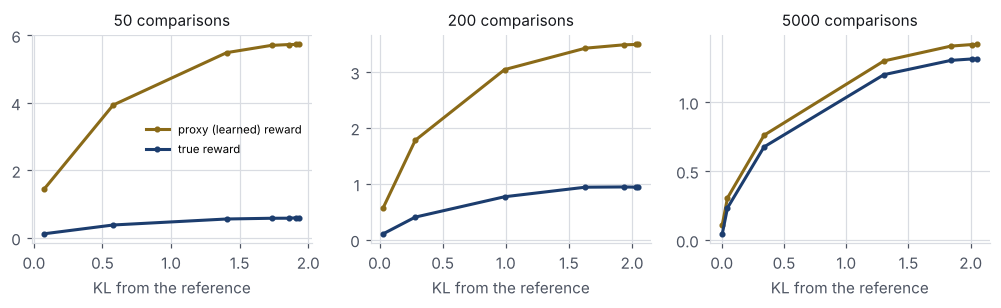

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(9.2, 2.9), sharey=False)
for a_, n in zip(ax, res):
    k = [r[1] for r in res[n]]
    a_.plot(k, [r[2] for r in res[n]], color=AMBER, lw=2, marker="o", ms=3, label="proxy (learned) reward")
    a_.plot(k, [r[3] for r in res[n]], color=NAVY, lw=2, marker="o", ms=3, label="true reward")
    a_.set_title(f"{n} comparisons", fontsize=10, color=INK); a_.set_xlabel("KL from the reference")
ax[0].legend(frameon=False, fontsize=7.5); plt.tight_layout(); plt.show()

Two things show up. First, the proxy is wildly optimistic. With 50 comparisons the optimized policy scores 5.7 on the learned reward and 0.6 on the true one, about ten times less. With 200 it is 3.5 against 0.94, and with 5,000 comparisons the two are close, 1.42 against 1.31. The learned reward is a poor measuring stick for a policy that has been optimized against it, and the fewer the comparisons the worse it is.
Second, and this is a result to take seriously because it is not what the usual story says: here the true reward does **not** fall. It rises and then plateaus, at a level set by the quality of the reward model, so over-optimizing costs nothing but the opportunity. In this tabular model each response has its own independent reward estimate, so the errors are noise, and picking the highest estimate among noisy ones is still better than picking at random.

## 4. When the reward model has an exploitable mistake

The failure called reward hacking needs more than noise. It needs a response that the reward model rates highly and that is actually bad: a mistake the policy can find and push towards. Real reward models have them, for example a preference for long, confident or flattering answers. We build one on purpose. Take the reward model fitted on 5,000 comparisons and, for every prompt, give the *worst* response a score equal to the model's favourite for that prompt (and in a second setting, 1.0 above it).
This is a constructed test of the mechanism and not a measurement of any real system.

the bad response is scored equal to the model's favourite
   beta      KL   proxy reward   true reward
  10.00    0.00           0.45         -0.01
   3.00    0.04           0.61          0.05
   1.00    0.27           0.97          0.13
   0.50    0.64           1.23          0.13
   0.30    0.93           1.35          0.09
   0.10    1.25           1.41         -0.00
   0.03    1.35           1.42         -0.04



the bad response is scored 1.0 above the model's favourite
   beta      KL   proxy reward   true reward
  10.00    0.01           0.61         -0.03
   3.00    0.07           0.89         -0.05
   1.00    0.53           1.60         -0.36
   0.50    1.31           2.15         -0.95
   0.30    1.83           2.36         -1.31
   0.10    2.08           2.42         -1.44
   0.03    2.08           2.42         -1.44



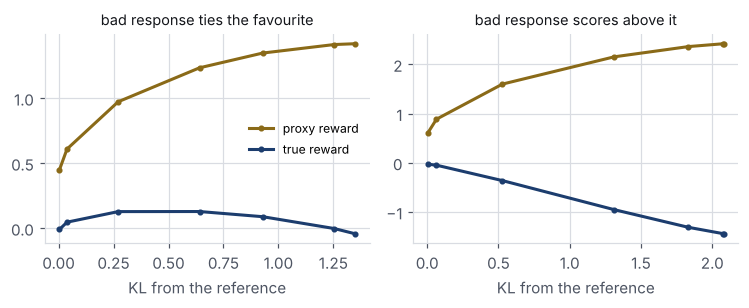

In [7]:
def exploited(seed, bonus):
    w, p, wi, lo = world_and_pairs(seed, 5000)
    rm = fit_reward_model(w, p, wi, lo, steps=300)
    rm2 = rm.clone(); rm2[torch.arange(6), w.true_r.argmin(1)] = rm.max(1).values + bonus
    return w, rm2
betas2 = (10.0, 3.0, 1.0, 0.5, 0.3, 0.1, 0.03)
res2 = {}
for bonus in (0.0, 1.0):
    rows = []
    for b in betas2:
        tr, px, ks = [], [], []
        for seed in range(20):
            w, rm2 = exploited(seed, bonus); ref = torch.zeros(6, 8)
            pol = kl_regularized_optimum(ref, rm2, b)
            tr.append(expected(pol, w.true_r)); px.append(expected(pol, rm2)); ks.append(kl(pol, torch.softmax(ref, -1)))
        rows.append((b, np.mean(ks), np.mean(px), np.mean(tr)))
    res2[bonus] = rows
    print(f"the bad response is scored {'equal to' if bonus == 0 else '1.0 above'} the model's favourite")
    print(f"{'beta':>7s} {'KL':>7s} {'proxy reward':>14s} {'true reward':>13s}")
    for b, k, pxm, trm in rows: print(f"{b:7.2f} {k:7.2f} {pxm:14.2f} {trm:13.2f}")
    print()
fig, ax = plt.subplots(1, 2, figsize=(7, 2.9))
for a_, bonus, t in zip(ax, res2, ("bad response ties the favourite", "bad response scores above it")):
    k = [r[1] for r in res2[bonus]]
    a_.plot(k, [r[2] for r in res2[bonus]], color=AMBER, lw=2, marker="o", ms=3, label="proxy reward")
    a_.plot(k, [r[3] for r in res2[bonus]], color=NAVY, lw=2, marker="o", ms=3, label="true reward")
    a_.set_title(t, fontsize=9.5, color=INK); a_.set_xlabel("KL from the reference")
ax[0].legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

This is **reward hacking**, and it is Goodhart's law in a few lines: when a measure becomes the target, it stops being a good measure. The proxy reward rises steadily as the policy moves away from the reference, because the policy finds the exploit. In the first setting the true reward rises a little, peaks at 0.13 at a moderate KL ($\beta$ near 0.5 to 1), and then falls back to where it started (-0.04 against -0.01 for the reference), so the extra optimization has bought nothing and the proxy says it has bought a great deal. In the second setting it falls to -1.44, the worst response in every prompt, because the policy has moved all its probability onto the bad responses.
When the exploit scores above the reward model's favourite there is no peak at all, and the true reward falls from the first step. The KL penalty is what keeps the policy inside the region where the reward model has been checked, and the right $\beta$ is found by watching a held-out measure of quality, never the proxy.

## 5. Direct Preference Optimization

DPO skips the reward model. Substituting $r = \beta \log (\pi^* / \pi_{\text{ref}}) + \text{const}$ into the Bradley-Terry likelihood gives a loss on the policy itself: $-\log \sigma\left(\beta\left[\log\frac{\pi(y_w)}{\pi_{\text{ref}}(y_w)} - \log\frac{\pi(y_l)}{\pi_{\text{ref}}(y_l)}\right]\right)$ for each preferred response $y_w$ and rejected response $y_l$. We train the policy table with this loss and compare it with the two-stage method (fit a reward model, then take the closed-form optimum for it), for the same $\beta = 0.5$ and the same comparisons.

In [8]:
print("comparisons   largest probability difference between the two policies   true reward: two-stage   DPO   best possible at this beta")
ref = torch.zeros(6, 8)
for n in (50, 200, 1000, 5000):
    diff, t2, td, tb = [], [], [], []
    for seed in range(20):
        w, p, wi, lo = world_and_pairs(seed, n)
        rm = fit_reward_model(w, p, wi, lo, steps=300)
        two = kl_regularized_optimum(ref, rm, 0.5)
        dpo = torch.softmax(train_dpo(ref, p, wi, lo, beta=0.5, steps=400), -1)
        diff.append((two - dpo).abs().max().item()); t2.append(expected(two, w.true_r)); td.append(expected(dpo, w.true_r))
        tb.append(expected(kl_regularized_optimum(ref, w.true_r, 0.5), w.true_r))
    print(f"{n:11d}   {np.mean(diff):57.4f}   {np.mean(t2):22.3f}   {np.mean(td):5.3f}   {np.mean(tb):10.3f}")

comparisons   largest probability difference between the two policies   true reward: two-stage   DPO   best possible at this beta


         50                                                      0.1518                    0.579   0.564        1.037


        200                                                      0.0363                    0.897   0.892        1.037


       1000                                                      0.0022                    1.001   1.000        1.037


       5000                                                      0.0009                    1.030   1.030        1.037


The two routes agree closely once there are a few hundred comparisons: the largest probability difference falls from 0.15 at 50 comparisons to 0.036 at 200 and below 0.003 from 1,000 on, and the true rewards agree to within 0.01 from 200 up. With 50 comparisons they differ more, because most responses were compared only a few times and each method fills the gaps differently, and both are trained for a fixed number of steps.
In this tabular setting DPO is not an approximation of the two-stage method but an equivalent way to solve it, with one network and one loss instead of two stages and a sampling loop. What it does not remove is the dependence on the data: a policy trained on 50 comparisons is as unreliable as the reward model that would have been fitted to them, and DPO has no proxy to watch because it never builds one. Its $\beta$ plays the same role as in Sections 3 and 4.

**Try it.** Give the reference policy a preference for one response by setting its logits to non-zero values and rerun Sections 2 to 4. Then flip 20% of the labels at random and see which method is more affected.